# Code de génération de trajectoire utile à la simulation en boucle fermée #

In [2]:
import numpy as np
import pandas as pd
from scipy.io import savemat
import matplotlib.pyplot as plt
from scipy.signal import butter, filtfilt

In [1]:
dt = 0.001

# Profile 1 : rampe de vitesse #

In [17]:
import random

Tr = 1
Vmax = 0.005 * 1000

Ttot = 150
dt = 0.001

Pf1 = []
time1 = np.arange(0, Ttot, dt)

def rampe(i, o, T):
    l = []
    t = 0

    while t < T-0.0005:
        l.append(i + (o - i) / T * t)
        t += dt

    return l


# Durée déjà générée
temps = 0

while temps < Ttot:

    # Choix aléatoire de la durée d'une rampe
    T = random.uniform(0.2, 4.0)

    # On évite de dépasser 150 s
    if temps + 4*T > Ttot:
        T = (Ttot - temps) / 4

    # 0 -> +Vmax
    Pf1 += rampe(0, Vmax, T)

    # +Vmax -> 0
    Pf1 += rampe(Vmax, 0, T)

    # 0 -> -Vmax
    Pf1 += rampe(0, -Vmax, T)

    # -Vmax -> 0
    Pf1 += rampe(-Vmax, 0, T)

    temps += 4*T

150000
150000


Text(0, 0.5, 'Pf1')

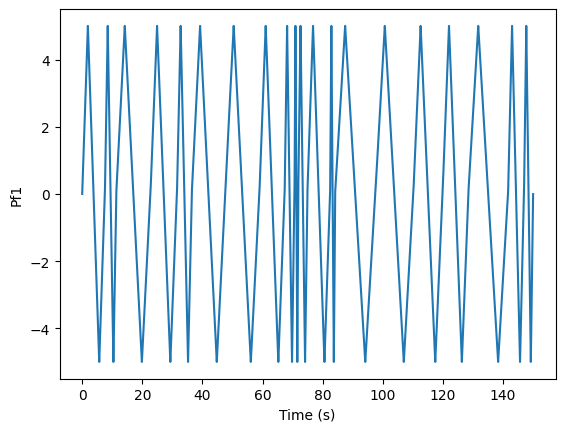

In [18]:
print (len(Pf1))
print (len(time1))

plt.plot(time1, Pf1)
plt.xlabel('Time (s)')
plt.ylabel('Pf1')

In [55]:
Tr = 1 
var = [4,2,1.8,1.6,1.4,1.2,1,0.8,0.6,0.4,0.2] 
Vmax = 0.005*1000 
Ttot = 15 
Pf1 = [] 
time1 = np.arange(0, Ttot, dt) 
def rampe(i, o, T): 
    l = [] 
    t = 0 
    while t < T-0.00000001: 
        l.append(i + (o - i) / T * t) 
        t += dt 
    return l 
for i in range (len(var)) : 
    vari = var[i]/4 
    Pf1 += rampe(0, Vmax, vari) 
    Pf1 += rampe(Vmax, 0, vari) 
    Pf1 += rampe(0, -1*Vmax, vari) 
    Pf1 += rampe(-1*Vmax, 0, vari)

15000
15000


Text(0, 0.5, 'Pf1')

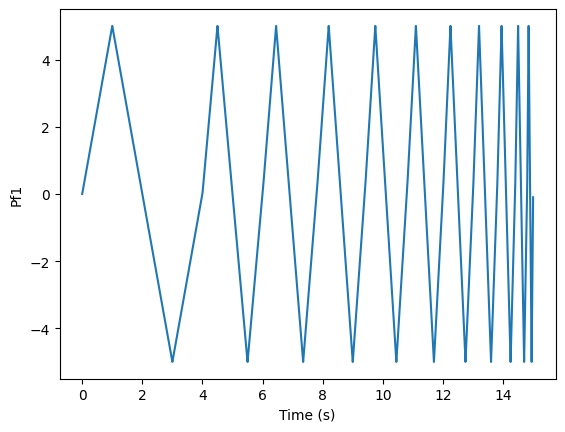

In [56]:
print (len(Pf1))
print (len(time1))

plt.plot(time1, Pf1)
plt.xlabel('Time (s)')
plt.ylabel('Pf1')

# Profil 2 : Paliers de vitesses #

In [57]:
Ttot = 15
Pf2 = []
time2 = np.arange(0, Ttot, dt)

delta = 1.5
seuil = delta
val = np.random.rand()
val = (val - 0.5)*Vmax*2

for t in time2:
    if t < seuil:
        Pf2.append(val)
    else:
        seuil += delta
        val = np.random.rand()
        val = (val - 0.5)*Vmax*2
        Pf2.append(val)


15000
15000


Text(0, 0.5, 'Pf2')

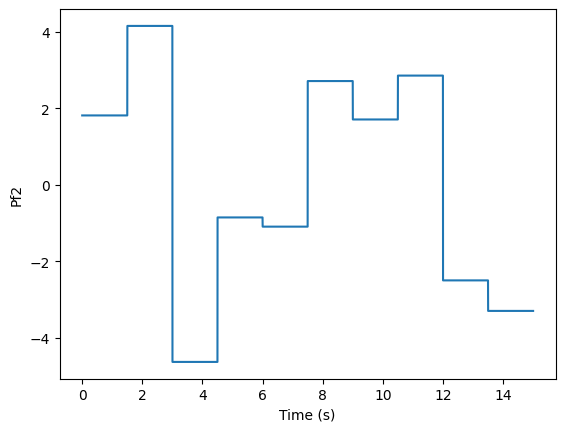

In [58]:
print (len(Pf2))
print (len(time2))

plt.plot(time2, Pf2)
plt.xlabel('Time (s)')
plt.ylabel('Pf2')

# Profile 3 : Oscilations lente #

In [34]:
A = 0.002*1000

Ttot = 15
Pf3 = []

tau = [5,1,2,4,3]
seuil = tau[0]
i = 0

time3 = np.arange(0, Ttot, dt)
for t in time3:
    if t < seuil:
        Pf3.append(A* np.sin(2 * np.pi * (1/tau[i]) * (t-seuil)))
    else:
        i += 1
        seuil += tau[i]
        Pf3.append(A* np.sin(2 * np.pi * (1/tau[i]) * (t-seuil)))    

15000
15000


Text(0, 0.5, 'Pf3')

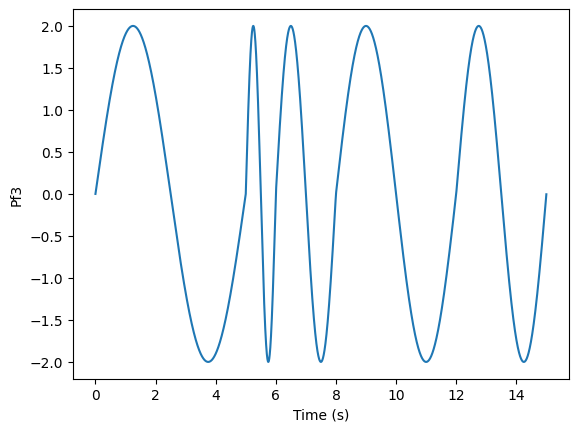

In [35]:
print (len(Pf3))
print (len(time3))

plt.plot(time3, Pf3)
plt.xlabel('Time (s)')
plt.ylabel('Pf3')

# Profile 4 : sinusoïde mutli freq #

In [12]:
A = Vmax

Ttot = 15
Pf4 = []
time4 = np.arange(0, Ttot, dt)

def Smf(t, A1, A2, A3, f1, f2, f3):
    return A*(A1 * np.sin(2 * np.pi * f1 * t) + A2 * np.sin(2 * np.pi * f2 * t) + A3 * np.sin(2 * np.pi * f3 * t))

for t in time4:
    if t < 5:
        Pf4.append(Smf(t, 1, 0.4, 0.2, 0.2, 2, 6))
    elif t < 7.5:
        Pf4.append(Smf(t, 1, 0.4, 0.2, 0.4, 4, 10))
    else:
        Pf4.append(Smf(t, 1, 0.4, 0.2, 2/15, 4/5, 8))

150000
150000


Text(0, 0.5, 'Pf4')

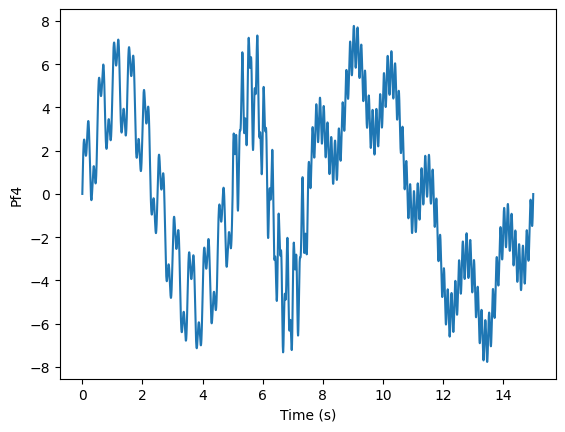

In [13]:
print (len(Pf4))
print (len(time4))

plt.plot(time4, Pf4)
plt.xlabel('Time (s)')
plt.ylabel('Pf4')

In [48]:
import numpy as np
import random

A = Vmax

Ttot = 150
Pf4 = []
time4 = np.arange(0, Ttot, dt)


def Smf(t, A1, A2, A3, f1, f2, f3):
    return A * (
        A1 * np.sin(2 * np.pi * f1 * t)
        + A2 * np.sin(2 * np.pi * f2 * t)
        + A3 * np.sin(2 * np.pi * f3 * t)
    )


# Durées possibles des différents blocs
durees = [
    2, 3, 4, 5, 7.5, 10, 15
]

temps = 0

while temps < Ttot:

    # Durée aléatoire du bloc
    duree_bloc = random.choice(durees)

    # Ne pas dépasser 150 s
    duree_bloc = min(duree_bloc, Ttot - temps)

    # Choix aléatoire des 3 fréquences
    f1 = random.choice([0.2, 0.4, 0.1, 0.6, 0.05])
    f2 = random.choice([0, 2, 4, 4/5, 6, 1])
    f3 = random.choice([0, 6, 10, 8, 15, 12])

    # Coefficients d'amplitude aléatoires
    A1 = random.choice([0.5, 0.8, 1.0])
    A2 = random.choice([0, 0.2, 0.4])
    A3 = random.choice([0, 0.1, 0.2])

    # Génération du bloc
    time_bloc = np.arange(temps, temps + duree_bloc, dt)

    for t in time_bloc:
        Pf4.append(
            Smf(t, A1, A2, A3, f1, f2, f3)
        )

    temps += duree_bloc


# Temps correspondant exactement au signal généré
time4 = np.arange(0, len(Pf4) * dt, dt)

150000
150000


Text(0, 0.5, 'Pf4')

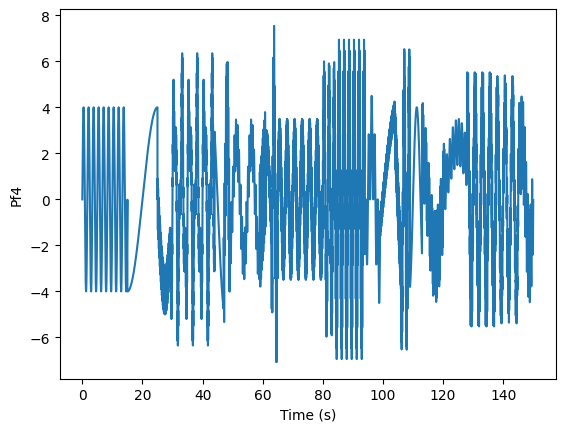

In [49]:
print (len(Pf4))
print (len(time4))

plt.plot(time4, Pf4)
plt.xlabel('Time (s)')
plt.ylabel('Pf4')

# Profile 5 & 6 : PRBS #

In [23]:
seg1 = np.array([0.65, 0.7, 0.75, 0.83 , 1, -0.65, -0.7, -0.75, -0.83 , -1])
seg1 = 0.0075* 1000 * seg1


Ttot = 150
Pf5 = []
time5 = np.arange(0, Ttot, dt)

cap = 0.02
n_cap = cap

cst = 0

for t in time5:
    if t >= n_cap:
        n_cap += cap
        cst = np.random.choice(seg1)

    Pf5.append(cst)

150000
150000


Text(0, 0.5, 'Pf5')

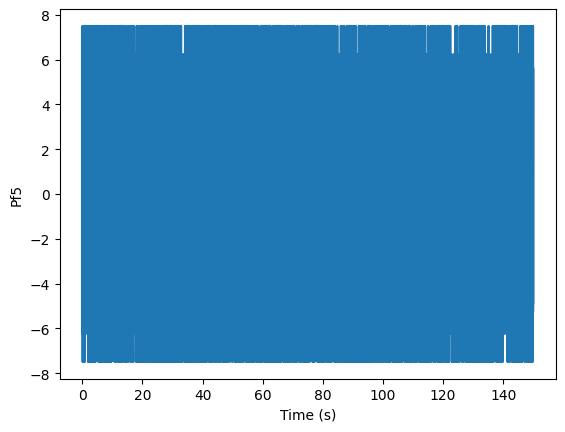

In [24]:
print (len(Pf5))
print (len(time5))

plt.plot(time5, Pf5)
plt.xlabel('Time (s)')
plt.ylabel('Pf5')

In [25]:
seg2 = np.array([0.52 ,0.5, 0.48, 0.43, 0.35 , -0.52, -0.5, -0.48, -0.43, -0.35])
seg2 = 0.002* 1000* seg2

Ttot = 150
Pf6 = []
time6 = np.arange(0, Ttot, dt)

cap = 0.02
n_cap = cap

cst = 0

for t in time6:
    if t >= n_cap:
        n_cap += cap
        cst = np.random.choice(seg2)

    Pf6.append(cst)

150000
150000


Text(0, 0.5, 'Pf6')

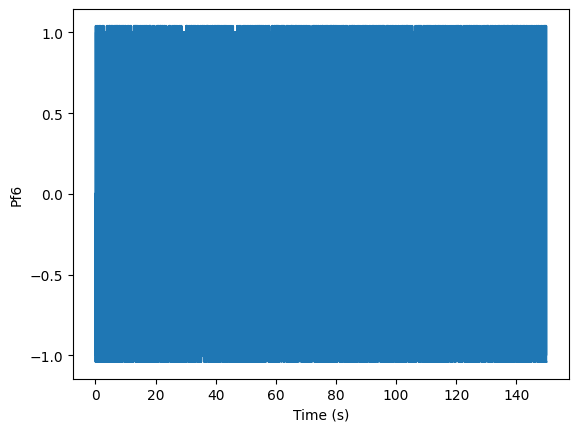

In [26]:
print (len(Pf6))
print (len(time6))

plt.plot(time6, Pf6)
plt.xlabel('Time (s)')
plt.ylabel('Pf6')

In [27]:
import numpy as np

def generate_chirp(t_end, dt, f_start, f_end, amplitude=1.0, method='linear'):
    """
    Génère un profil de vitesse chirp (balayage fréquentiel).

    Paramètres
    ----------
    t_end     : durée totale (s)
    dt        : pas de temps (s)
    f_start   : fréquence initiale (Hz)
    f_end     : fréquence finale (Hz)
    amplitude : amplitude maximale (m/s)
    method    : 'linear' ou 'logarithmic'

    Retourne
    --------
    t         : vecteur temps
    velocity  : profil de vitesse (m/s)
    """
    t = np.arange(0, t_end, dt)

    if method == 'linear':
        # Fréquence instantanée : f(t) = f_start + (f_end - f_start) * t / t_end
        # Phase intégrée        : φ(t) = 2π * [f_start*t + (f_end-f_start)*t²/(2*t_end)]
        k = (f_end - f_start) / t_end
        phase = 2 * np.pi * (f_start * t + 0.5 * k * t**2)

    elif method == 'logarithmic':
        # Fréquence instantanée : f(t) = f_start * (f_end/f_start)^(t/t_end)
        # Phase intégrée (analytique)
        ratio = f_end / f_start
        phase = 2 * np.pi * f_start * t_end / np.log(ratio) * (ratio**(t / t_end) - 1)

    velocity = amplitude * np.sin(phase)
    return t, velocity

In [28]:
def generate_colored_noise(t_end, dt, alpha=1.0, amplitude=1.0,
                           f_low_cut=0.1, f_high_cut=100.0, seed=None):
    """
    Génère un bruit coloré avec densité spectrale en 1/f^alpha.

    alpha = 0  → bruit blanc   (toutes fréquences égales)
    alpha = 1  → bruit rose    (bon compromis dynamique/basse-fréq)
    alpha = 2  → bruit brun    (dominante basse fréquence, lent)

    Paramètres
    ----------
    t_end      : durée totale (s)
    dt         : pas de temps (s)
    alpha      : exposant spectral
    amplitude  : amplitude RMS cible (m/s)
    f_low_cut  : coupure basse (Hz) — évite la dérive DC
    f_high_cut : coupure haute (Hz) — filtre les fréquences hors système
    seed       : graine aléatoire pour reproducibilité

    Retourne
    --------
    t          : vecteur temps
    velocity   : profil de vitesse (m/s)
    """
    rng = np.random.default_rng(seed)
    n = int(t_end / dt)
    freqs = np.fft.rfftfreq(n, d=dt)          # fréquences positives

    # Spectre d'amplitude blanc
    white_spectrum = rng.standard_normal(len(freqs)) + 1j * rng.standard_normal(len(freqs))

    # Pondération spectrale 1/f^(alpha/2) sur les amplitudes
    # (alpha/2 car on travaille sur les amplitudes, pas la puissance)
    power = np.ones(len(freqs))
    nonzero = freqs > 0
    power[nonzero] = freqs[nonzero] ** (-alpha / 2.0)

    # Coupures basse et haute fréquence
    power[freqs < f_low_cut]  = 0.0
    power[freqs > f_high_cut] = 0.0

    colored_spectrum = white_spectrum * power

    # Retour dans le domaine temporel
    noise = np.fft.irfft(colored_spectrum, n=n)

    # Normalisation à l'amplitude RMS cible
    noise = noise / (np.std(noise) + 1e-12) * amplitude

    t = np.arange(n) * dt
    return t, noise

In [29]:
v_max = Vmax      # m/s — à adapter à ton chariot

# Chirp logarithmique : 0.01 Hz → 200 Hz sur 60 s
t_c, v_chirp = generate_chirp(150, dt, f_start=0.01, f_end=200,
                               amplitude=v_max, method='logarithmic')

# Bruit rose (alpha=1) limité à [0.5 Hz, 150 Hz]
t_n, v_noise = generate_colored_noise(150, dt, alpha=1.0, amplitude=0.3*v_max,
                                       f_low_cut=0.5, f_high_cut=150.0, seed=42)

# Superposition chirp + bruit pour enrichir la corrélation (v, a)
v_combined = np.clip(v_chirp + v_noise, -v_max, v_max)

150000
150000


Text(0, 0.5, 'Pf6')

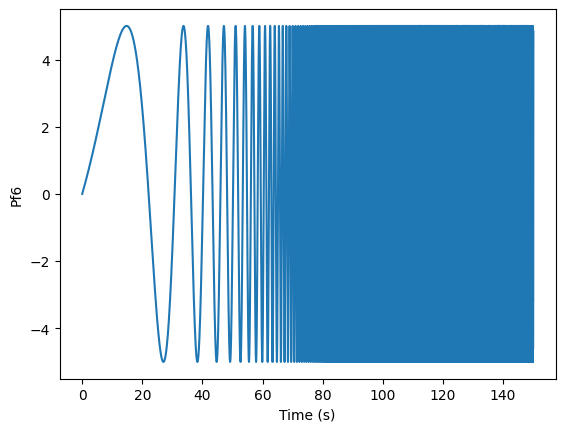

In [30]:
print (len(v_chirp))
print (len(t_c))

plt.plot(t_c, v_chirp)
plt.xlabel('Time (s)')
plt.ylabel('Pf6')

150000
150000


Text(0, 0.5, 'Pf6')

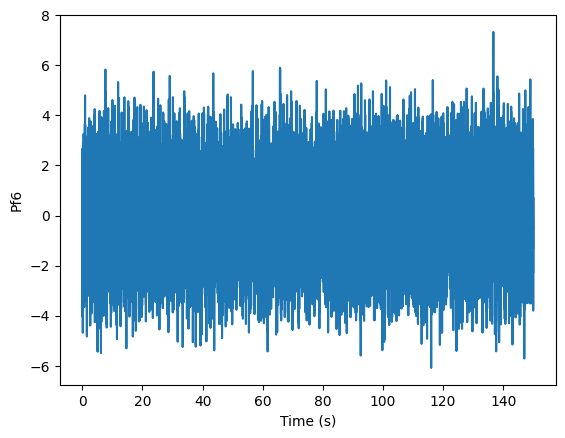

In [31]:
print (len(v_noise))
print (len(t_n))

plt.plot(t_n, v_noise)
plt.xlabel('Time (s)')
plt.ylabel('Pf6')

150000
150000


Text(0, 0.5, 'Pf6')

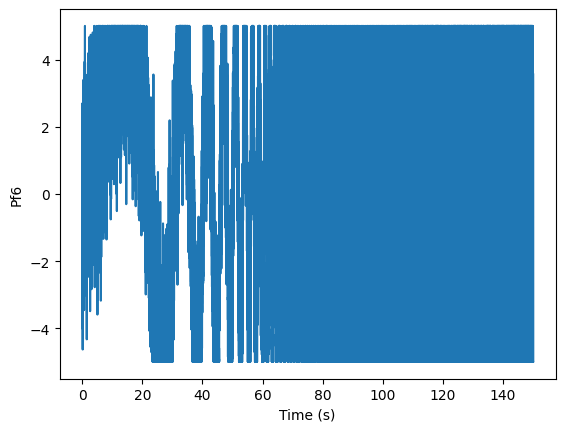

In [32]:
print (len(v_combined))
print (len(t_n))

plt.plot(t_n, v_combined)
plt.xlabel('Time (s)')
plt.ylabel('Pf6')

In [50]:
interval = 0.5
#interval = 5

l_pf = {1: Pf1, 2: Pf2, 3: Pf3, 4: Pf4, 5: Pf5, 6: Pf6, 7: v_chirp, 8: v_noise, 9: v_combined}
l_time = {1: time1, 2: time2, 3: time3, 4: time4, 5: time5, 6: time6, 7: t_c, 8: t_n, 9:t_n}

In [51]:
def gather(Pf,time,nb_Pf,L):
    time.append(0)
    for i in L:
        inter = np.arange(time[-1], time[-1] + interval, dt)
        time += inter.tolist()
        Pf += [0] * len(inter)
        nb_Pf += [i]*len(inter)

        time += [time[-1] + x for x in l_time[i]]
        Pf += [v for v in l_pf[i]]
        nb_Pf += [i]*len(l_pf[i])

        inter = np.arange(time[-1], time[-1] + interval, dt)
        time += inter.tolist()
        Pf += [0] * len(inter)
        nb_Pf += [i]*len(inter)

    time.pop(0)
    return Pf, time, nb_Pf

In [52]:
Pf = []
time = []
nb_Pf = []

# Pf, time, nb_Pf = gather(Pf, time, nb_Pf, [1, 2, 3, 4, 5, 6, 7, 8, 9])
Pf, time, nb_Pf = gather(Pf, time, nb_Pf, [1, 2, 4, 5, 6, 8])


print(len(Pf))
print(len(time))
print(len(nb_Pf))

df = pd.DataFrame({
    'Force': Pf,
    'time': time,
    'prof': nb_Pf
})

# Conversion en dictionnaire compatible MATLAB
mat_dict = {col: df[col].to_numpy() for col in df.columns}

# Sauvegarde dans un fichier .mat
savemat('input_bf_sim.mat', mat_dict)



906000
906000
906000


906000
906000


Text(0, 0.5, 'Pf')

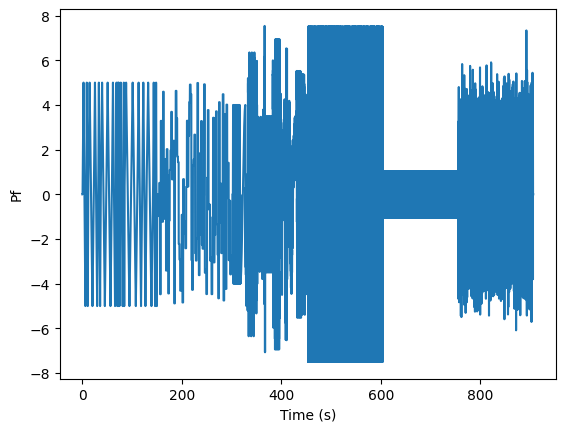

In [53]:
print (len(Pf))
print (len(time))

plt.plot(time, Pf)
plt.xlabel('Time (s)')
plt.ylabel('Pf')